In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.optimize import brentq

from numcosmo_ep2 import lpt, spt, growth

In [2]:
L = 500.0          # Mpc/h
N = 256
seed = 1234

dx = L / N
V = L**3

kf = 2.0 * np.pi / L
kNy = np.pi * N / L

omega_b = 0.0224
omega_cdm = 0.120
omega_m = omega_b + omega_cdm
omega_lambda = 1 - omega_m
h = 0.674

dealiasing_frac = 2./3.

print(f"N              = {N}")
print(f"L              = {L:.1f} Mpc/h")
print(f"dx             = {dx:.4f} Mpc/h")
print(f"k_fundamental  = {kf:.5f} h/Mpc")
print(f"k_Nyquist      = {kNy:.5f} h/Mpc")

N              = 256
L              = 500.0 Mpc/h
dx             = 1.9531 Mpc/h
k_fundamental  = 0.01257 h/Mpc
k_Nyquist      = 1.60850 h/Mpc


In [3]:
pk_data = np.loadtxt("../outputs/class/base_pk.dat")

k_class = pk_data[:, 0]
P_class = pk_data[:, 1]

logP_interp = interp1d(np.log(k_class), np.log(P_class), kind="linear", bounds_error=True)

def classPower(k):
    k = np.asarray(k)

    P = np.zeros_like(k, dtype=float)
    mask = k > 0.0

    P[mask] = np.exp(logP_interp(np.log(k[mask])))

    return P

_, _, _, _, _, _, kmag = lpt.fourierGrid(N, L)

print(f"CLASS k range = [{k_class.min():.4g}, {k_class.max():.4g}] h/Mpc")
print(f"Grid |k| max  = {kmag.max():.4g} h/Mpc")

CLASS k range = [1.048e-05, 6.694] h/Mpc
Grid |k| max  = 2.786 h/Mpc


# Second order density field $\delta_2$ (2a)

The second order field is defined by a prescription of mode coupling between multiple values of frequency in Fourier space

\begin{equation}
\delta_{\mathrm{2,}\mathbf{k}}=\frac{1}{V} \sum_{\mathbf{q}}F_2(\mathbf{q},\mathbf{k}-\mathbf{q})\delta_\mathrm{1,\mathbf{q}}\delta_\mathrm{1,\mathbf{k}-\mathbf{q}},
\end{equation}

with the kernel

\begin{equation}
F_2(\mathbf{k}_1,\mathbf{k}_2)=\frac{5}{7}+\frac{1}{2}\mu\left(\frac{k_1}{k_2}+\frac{k_2}{k_1}\right)+\frac{2}{7}\mu^2,
\end{equation}

where $\mu\equiv\hat{\mathbf{k}}_1\cdot\hat{\mathbf{k}}_2$. This sum, however, is very heavy computationally since, for a grid resolution of $N^3$, the number of necessary operations scales with $\mathcal{O}(N^6)$. The alternative is to perform this convolution in real space, since by using FFT the operation cost will reduce to $\mathcal{O}(N^3\log N)$. In real space, the second order field is:

\begin{equation}
\delta_2(\mathbf{x})=\frac{17}{21}\delta_1^2(\mathbf{x})-\Psi_1(\mathbf{x})\cdot\nabla\delta_1(\mathbf{x})+\frac{2}{7}s_{ij}(\mathbf{x})s_{ij}(\mathbf{x}),
\end{equation}

with the quantities defined in Fourier space as:

\begin{equation}
\Psi_{1,j}(\mathbf{k})=j\frac{k_j}{k^2}\delta_1(\mathbf{k}),
\end{equation}

and

\begin{equation}
s_{ij}(\mathbf{k})=\left(\frac{k_ik_j}{k^2}-\frac{1}{3}\delta_{ij}\right)\delta_1(\mathbf{k}),
\end{equation}

and their real versions through IFFT as $\Psi_j(\mathbf{x})=\mathcal{F}^{-1}\bigg[\Psi_j(\mathbf{k})\bigg]$ and $s_{ij}(\mathbf{x})=\mathcal{F}^{-1}\bigg[s_{ij}(\mathbf{k})\bigg]$.

The term $\frac{17}{21}\sigma_1^2$ is the local field response, $-\Psi_1\cdot\nabla\delta_1$ is the advection, and $\frac{2}{7}s_{ij}s_{ij}$ the tidal contribution.

In [6]:
# Reference Gaussian field at D = 1
delta_ref_k, _ = lpt.gaussianField(N, L, classPower, seed=seed)

# Fourier grid
_, _, kx, ky, kz, k2, kmag = lpt.fourierGrid(N, L)

# Same de-aliasing mask used in the SPT calculation
mask = spt.dealiasMask(kx, ky, kz, kNy, fraction=dealiasing_frac)

delta_ref_filtered_k = delta_ref_k * mask
delta_ref_filtered_k[0, 0, 0] = 0.0

delta_ref_filtered_x = np.fft.irfftn(delta_ref_filtered_k / dx**3, s=(N, N, N),axes=(0, 1, 2))
sigma_ref = delta_ref_filtered_x.std()
sigma_target = 0.20

D_spt = sigma_target / sigma_ref
a_spt = brentq(lambda a: growth.D_of_a(a, omega_m0=omega_m, omega_lambda0=omega_lambda) - D_spt, 1e-4, 1.0)
z_spt = 1.0 / a_spt - 1.0

# First order field
delta1_k = D_spt * delta_ref_filtered_k
delta1_k[0, 0, 0] = 0.0
delta1_x = np.fft.irfftn(delta1_k / dx**3, s=(N, N, N), axes=(0, 1, 2))

# Second-order SPT field
delta2_k, delta2_x = spt.secondOrderDensity(delta1_k, N, L, dealias=True)

delta12_k = delta1_k + delta2_k
delta12_x = delta1_x + delta2_x

In [5]:
# ------------------------------------------------------------
# SPT field diagnostics
# ------------------------------------------------------------

# Reference-field variance before and after de-aliasing
delta_ref_x = np.fft.irfftn(delta_ref_k / dx**3, s=(N, N, N), axes=(0, 1, 2))

sigma_ref_raw = np.std(delta_ref_x)
sigma_ref_filtered = np.std(delta_ref_filtered_x)

variance_retained = sigma_ref_filtered**2 / sigma_ref_raw**2

# ------------------------------------------------------------
# Means
# ------------------------------------------------------------

mean1 = np.mean(delta1_x)
mean2 = np.mean(delta2_x)
mean12 = np.mean(delta12_x)

# ------------------------------------------------------------
# RMS fluctuations / standard deviations
# ------------------------------------------------------------

sigma1 = np.std(delta1_x)
sigma2 = np.std(delta2_x)
sigma12 = np.std(delta12_x)

# ------------------------------------------------------------
# Linear-second-order covariance
# ------------------------------------------------------------

cov12 = np.mean((delta1_x - mean1) * (delta2_x - mean2))
corr12 = cov12 / (sigma1 * sigma2)

# ------------------------------------------------------------
# Check that the requested linear variance was obtained
# ------------------------------------------------------------

sigma_target_error = (sigma1 - sigma_target) / sigma_target


print("SPT field diagnostics")
print("=====================")

print("\nAmplitude / epoch")
print("-----------------")
print(f"D_spt                      = {D_spt:.6f}")
print(f"a_spt                      = {a_spt:.6f}")
print(f"z_spt                      = {z_spt:.3f}")
print(f"target sigma(delta1)       = {sigma_target:.6f}")
print(f"measured sigma(delta1)     = {sigma1:.6f}")
print(f"relative target error      = {sigma_target_error:+.3e}")

print("\nMean-density checks")
print("-------------------")
print(f"<delta1>                   = {mean1:+.4e}")
print(f"<delta2>                   = {mean2:+.4e}")
print(f"<delta1 + delta2>          = {mean12:+.4e}")

print("\nPerturbative hierarchy")
print("----------------------")
print(f"sigma(delta1)              = {sigma1:.6f}")
print(f"sigma(delta2)              = {sigma2:.6f}")
print(f"sigma(delta1 + delta2)     = {sigma12:.6f}")
print(f"sigma2 / sigma1            = {sigma2/sigma1:.6f}")

print("\nLinear / second-order coupling")
print("------------------------------")
print(f"<delta1 delta2>_c          = {cov12:+.4e}")
print(f"corr(delta1, delta2)       = {corr12:+.4e}")

print(f"\n{dealiasing_frac:.2f} de-aliasing")
print("----------------")
print(f"sigma_ref raw              = {sigma_ref_raw:.6f}")
print(f"sigma_ref filtered         = {sigma_ref_filtered:.6f}")
print(f"variance retained          = {variance_retained:.6f}")
print(f"variance removed           = {1.0 - variance_retained:.6f}")

SPT field diagnostics

Amplitude / epoch
-----------------
D_spt                      = 0.093659
a_spt                      = 0.060773
z_spt                      = 15.455
target sigma(delta1)       = 0.200000
measured sigma(delta1)     = 0.200000
relative target error      = +1.110e-15

Mean-density checks
-------------------
<delta1>                   = +1.6771e-19
<delta2>                   = -4.7646e-21
<delta1 + delta2>          = -3.4559e-19

Perturbative hierarchy
----------------------
sigma(delta1)              = 0.200000
sigma(delta2)              = 0.085310
sigma(delta1 + delta2)     = 0.217442
sigma2 / sigma1            = 0.426551

Linear / second-order coupling
------------------------------
<delta1 delta2>_c          = +1.6965e-06
corr(delta1, delta2)       = +9.9430e-05

0.67 de-aliasing
----------------
sigma_ref raw              = 2.536395
sigma_ref filtered         = 2.135414
variance retained          = 0.708811
variance removed           = 0.291189


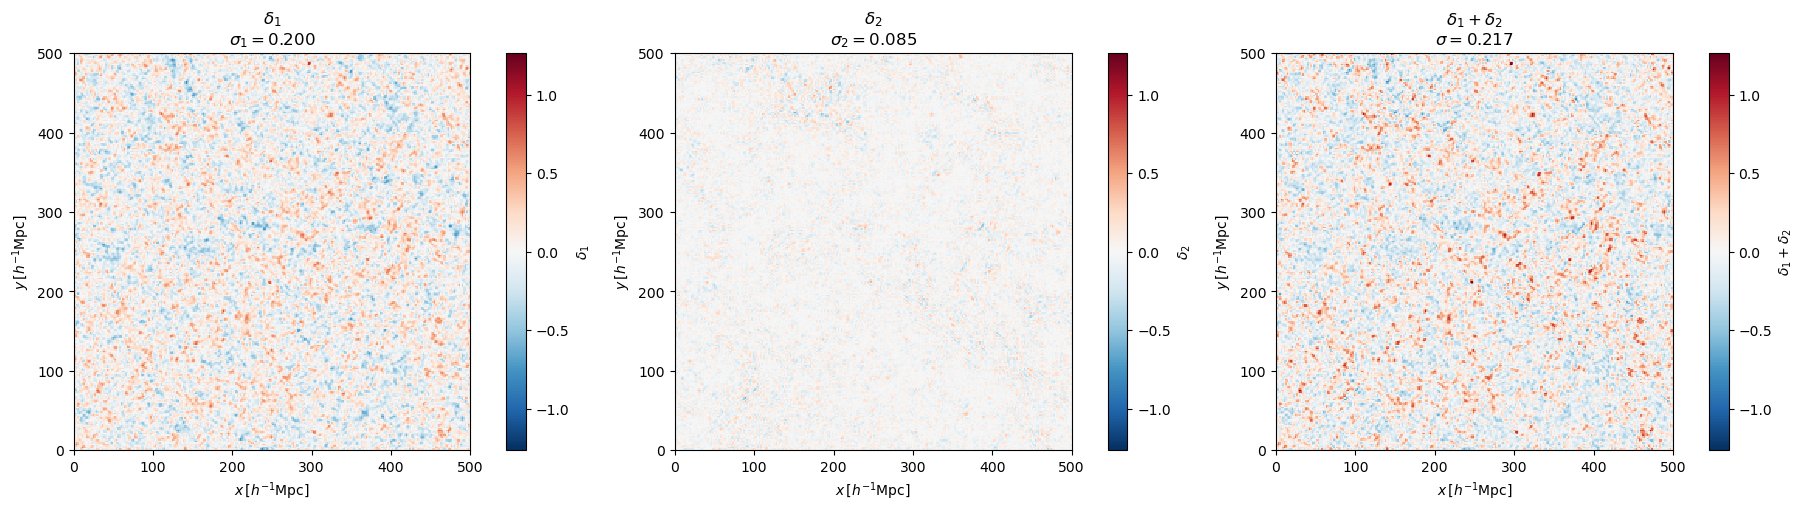

In [6]:
iz = N // 2

slice1 = delta1_x[:, :, iz]
slice2 = delta2_x[:, :, iz]
slice12 = delta12_x[:, :, iz]

# Same scale for all deltas
vmain = max(np.max(np.abs(slice1)), np.max(np.abs(slice12)))

fig, ax = plt.subplots(ncols=3, figsize=(18, 5), sharex=True, layout="constrained")

im0 = ax[0].imshow(slice1.T, origin="lower", extent=(0, L, 0, L), cmap="RdBu_r",
                     vmin=-vmain, vmax=vmain, interpolation="nearest")
ax[0].set_title(rf"$\delta_1$"+"\n"+rf"$\sigma_1={sigma1:.3f}$")

im1 = ax[1].imshow(slice2.T, origin="lower", extent=(0, L, 0, L), cmap="RdBu_r",
                     vmin=-vmain, vmax=vmain, interpolation="nearest")
ax[1].set_title(rf"$\delta_2$"+"\n"+rf"$\sigma_2={sigma2:.3f}$")

im2 = ax[2].imshow(slice12.T, origin="lower", extent=(0, L, 0, L), cmap="RdBu_r",
                     vmin=-vmain, vmax=vmain, interpolation="nearest")
ax[2].set_title(rf"$\delta_1+\delta_2$"+"\n"+rf"$\sigma={sigma12:.3f}$")

for ax_i in ax:
    ax_i.set_xlabel(r"$x\,[h^{-1}{\rm Mpc}]$")
    ax_i.set_ylabel(r"$y\,[h^{-1}{\rm Mpc}]$")
    ax_i.set_aspect("equal")

fig.colorbar(im0, ax=ax[0], label=r"$\delta_1$")
fig.colorbar(im1, ax=ax[1], label=r"$\delta_2$")
fig.colorbar(im2, ax=ax[2], label=r"$\delta_1+\delta_2$")

plt.savefig("../outputs/figures/02_delta_1_2.png", dpi=200)
plt.show()

We show the field sobredensities of the gaussian $\delta_1$ (left panel) and second order SPT correction $\delta_2$ (middle panel). Their sum is shown in the right panel. Although $\delta_2$ has a smaller amplitude, and more local corretion ($\sigma_2<\sigma_1$) we can see that it generates a non-negligible structure on the final $\delta_1+\delta_2$ structure, amplitude and dispersion.

# $\delta_1,\delta_2$ statistics (2b)

In [7]:
kmax_analysis = 0.3 * kNy
bins = np.arange(0.5 * kf, kmax_analysis + 1.5 * kf, kf)

# Linear theoretical spectrum at the same epoch
Plinear_grid = D_spt**2 * classPower(kmag)

kbin, P11, Nmodes = lpt.shellAveragePower(delta1_k, kmag, L, N,bins)
_, P22, _ = lpt.shellAveragePower(delta2_k, kmag, L, N, bins)
_, Ptotal, _ = lpt.shellAveragePower(delta12_k, kmag, L, N, bins)
_, Plinear = lpt.shellAverageInputPower(kmag, Plinear_grid, N, bins)
_, P12, _ = spt.shellAverageCrossPower(delta1_k, delta2_k, kmag, L, N, bins)

In [8]:
Psum = P11 + 2.0 * P12 + P22
power_identity_residual = np.max(np.abs(Ptotal - Psum) / np.maximum(Ptotal, 1e-300))

print(f"max relative residual Ptot = P11 + 2P12 + P22 : {power_identity_residual:.3e}")

max relative residual Ptot = P11 + 2P12 + P22 : 2.166e-14


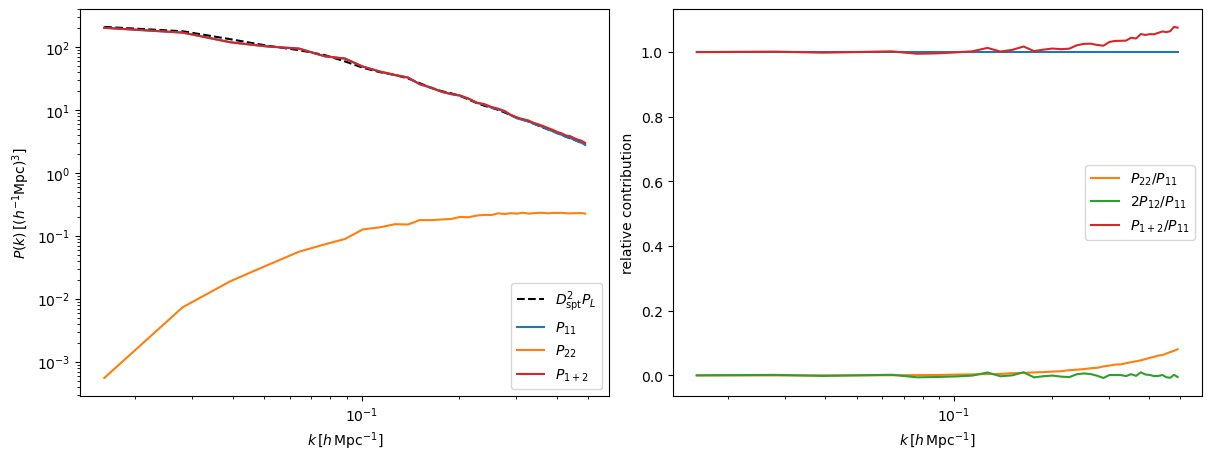

In [42]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained", sharex=True)

# ------------------------------------------------------------
# Absolute spectra
# ------------------------------------------------------------

ax[0].loglog(kbin, Plinear, c="k", ls="--", label=r"$D_{\rm spt}^2 P_L$")
ax[0].loglog(kbin, P11, label=r"$P_{11}$")
ax[0].loglog(kbin, P22, label=r"$P_{22}$")
ax[0].loglog(kbin, Ptotal, label=r"$P_{1+2}$", c="C3")

ax[0].set_xlabel(r"$k\,[h\,\mathrm{Mpc}^{-1}]$")
ax[0].set_ylabel(r"$P(k)\,[(h^{-1}\mathrm{Mpc})^3]$")
ax[0].legend()

# ------------------------------------------------------------
# Relative nonlinear contributions
# ------------------------------------------------------------

ax[1].plot(kbin, P11 / P11, c="C0")
ax[1].plot(kbin, P22 / P11, label=r"$P_{22}/P_{11}$", c="C1")
ax[1].plot(kbin, 2.0 * P12 / P11, label=r"$2P_{12}/P_{11}$", c="C2")
ax[1].plot(kbin, Ptotal / P11, label=r"$P_{1+2}/P_{11}$", c="C3")

ax[1].set_xlabel(r"$k\,[h\,\mathrm{Mpc}^{-1}]$")
ax[1].set_ylabel("relative contribution")
ax[1].set_xscale("log")
ax[1].legend()

plt.savefig("../outputs/figures/02_spectra.png", dpi=200)
plt.show()

Power spectra of the two fields compared to the input power spectra (black dashed line). As seen before, the linear spectra $P_{11}$ follows the input $D^2_{spt}P_L(k)$ very well through the observed region of $k<0.3k_\mathrm{Ny}$.

The addition of $\delta_2$ has a subdominant effect on the spectra, with $P_\mathrm{22}\ll P_\mathrm{11}$, but grows with frequency $k$. This is the expected effect of mode-coupling where two modes contribute to the final power spectra together.

The cross-term $P_\mathrm{12}$ is negligible and equivalent to zero $\langle P_\mathrm{12}$ consistent with the gaussian initial conditions. We also find that $P_\mathrm{1+2}=P_\mathrm{11}+2P_\mathrm{21}+P_\mathrm{22}$ correctly. One should note, however, that this is not the complete one loop SPT power spectra $P_\mathrm{1-loop}=P_\mathrm{11}+P_\mathrm{22}+2P_\mathrm{13}$ since it requires the term $P_\mathrm{13}$, which is not in our scope to implement.

In [19]:
def gaussianWindow(kmag, R):
    return np.exp(-0.5 * (kmag * R)**2)


def smoothField(delta_k, kmag, R, N, L):
    dx = L / N
    W = gaussianWindow(kmag, R)

    return np.fft.irfftn(
        delta_k * W / dx**3,
        s=(N, N, N),
        axes=(0, 1, 2)
    )

def reducedSkewness(delta_x):
    field = delta_x - delta_x.mean()

    var = np.mean(field**2)
    m3 = np.mean(field**3)

    sigma = np.sqrt(var)

    gamma1 = m3 / sigma**3
    S3 = m3 / var**2

    return S3, var, m3, gamma1

In [28]:
R_values = np.array([2.0, 5.0, 10.0, 15.0, 20.0, 30.0])  # Mpc/h
S3_linear = []
S3_spt = []
gm1_linear = []
gm1_spt = []

for R in R_values:
    delta1_R = smoothField(delta1_k, kmag, R, N, L)
    delta12_R = smoothField(delta12_k, kmag, R, N, L)

    S3_1, var1, m3_1, gm1_1 = reducedSkewness(delta1_R)
    S3_12, var12, m3_12, gm1_12 = reducedSkewness(delta12_R)

    S3_linear.append(S3_1)
    S3_spt.append(S3_12)
    gm1_linear.append(gm1_1)
    gm1_spt.append(gm1_12)

    print(
        f"R = {R:5.1f} Mpc/h   "
        f"S3(delta1) = {S3_1:+.5f}   "
        f"S3(delta1+delta2) = {S3_12:+.5f}"
        f"gamma1(delta1) = {gm1_1:+.5f}   "
        f"gamma1(delta1+delta2) = {gm1_12:+.5f}"
    )

S3_linear = np.asarray(S3_linear)
S3_spt = np.asarray(S3_spt)

R =   2.0 Mpc/h   S3(delta1) = -0.01248   S3(delta1+delta2) = +3.54995gamma1(delta1) = -0.00142   gamma1(delta1+delta2) = +0.41189
R =   5.0 Mpc/h   S3(delta1) = -0.05994   S3(delta1+delta2) = +3.63211gamma1(delta1) = -0.00373   gamma1(delta1+delta2) = +0.22715
R =  10.0 Mpc/h   S3(delta1) = -0.84348   S3(delta1+delta2) = +2.70334gamma1(delta1) = -0.02972   gamma1(delta1+delta2) = +0.09533
R =  15.0 Mpc/h   S3(delta1) = -2.15327   S3(delta1+delta2) = +1.25896gamma1(delta1) = -0.05112   gamma1(delta1+delta2) = +0.02989
R =  20.0 Mpc/h   S3(delta1) = -2.68669   S3(delta1+delta2) = +0.61252gamma1(delta1) = -0.04668   gamma1(delta1+delta2) = +0.01064
R =  30.0 Mpc/h   S3(delta1) = -4.37723   S3(delta1+delta2) = -1.12052gamma1(delta1) = -0.04722   gamma1(delta1+delta2) = -0.01209


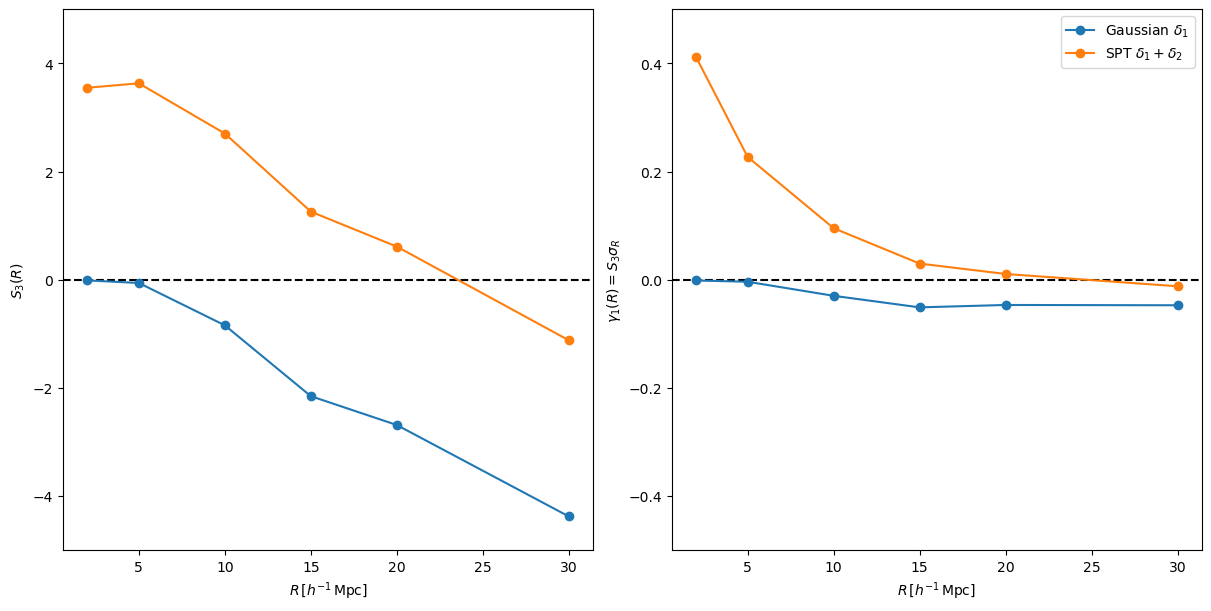

In [31]:
fig, ax = plt.subplots(ncols=2, figsize=(12, 6), layout="constrained")

ax[0].axhline(0.0, color="k", ls="--")
ax[0].plot(R_values, S3_linear, "o-", label=r"Gaussian $\delta_1$")
ax[0].plot(R_values, S3_spt, "o-", label=r"SPT $\delta_1+\delta_2$")

ax[0].set_ylim(-5,5)
ax[0].set_xlabel(r"$R\,[h^{-1}\,\mathrm{Mpc}]$")
ax[0].set_ylabel(r"$S_3(R)$")

ax[1].axhline(0.0, color="k", ls="--")
ax[1].plot(R_values, gm1_linear, "o-", label=r"Gaussian $\delta_1$")
ax[1].plot(R_values, gm1_spt, "o-", label=r"SPT $\delta_1+\delta_2$")

ax[1].set_ylim(-0.5,0.5)
ax[1].set_xlabel(r"$R\,[h^{-1}\,\mathrm{Mpc}]$")
ax[1].set_ylabel(r"$\gamma_1(R)=S_3\sigma_R$")
ax[1].legend()

plt.savefig("../outputs/figures/02_s3.png", dpi=200)
plt.show()

It is expected that the linear gaussian field $\sigma_1$ should have its third moment equal to zero. In a finite realization, however, $S_3(R)$ has fluctuations that grow in modulus for higher values of $R$. This is a consequence of a lower $\sigma_R$ such that the normalization $\sigma_R^4$ in

\begin{equation}
S_3(R)\equiv\frac{\langle\delta^3\rangle}{\langle\delta^2\rangle^2}=\frac{\langle\delta^3\rangle}{\sigma_R^4}
\end{equation}
amplifies statistic fluctuations. This is confirmed by the right panel that shows the padronized skewness $\gamma_1=S_3\sigma_R$ that remains small for the gaussian $\delta_1$ field. However, for the SPT $\delta_1+\delta_2$ field we can observe a significant value of $\delta_1$ at small scales. This shows a non-gaussianity as a consequence of the second order corretion.

# Ensamble higher order statistics (2c)

In [24]:
seeds = list(range(20))
R_values = np.array([2.0, 5.0, 10.0, 15.0, 20.0, 30.0])

higher_ensemble = spt.runHigherOrderEnsemble(N=N, L=L, seeds=seeds, D_spt=D_spt,
                                             classPower=classPower, R_values=R_values,
                                             dealiasing_frac=dealiasing_frac)

5/20 realizations
10/20 realizations
15/20 realizations
20/20 realizations


In [25]:
def meanSem(x):
    n = x.shape[0]
    return np.mean(x, axis=0), np.std(x, axis=0, ddof=1) / np.sqrt(n)


S3g_mean, S3g_sem = meanSem(higher_ensemble["S3_g"])
S3spt_mean, S3spt_sem = meanSem(higher_ensemble["S3_spt"])
gammag_mean, gammag_sem = meanSem(higher_ensemble["gamma_g"])
gammaspt_mean, gammaspt_sem = meanSem(higher_ensemble["gamma_spt"])
m3g_mean, m3g_sem = meanSem(higher_ensemble["m3_g"])
m3spt_mean, m3spt_sem = meanSem(higher_ensemble["m3_spt"])

In [26]:
delta_S3 = higher_ensemble["S3_spt"] - higher_ensemble["S3_g"]
delta_gamma = higher_ensemble["gamma_spt"] - higher_ensemble["gamma_g"]

deltaS3_mean, deltaS3_sem = meanSem(delta_S3)
deltaGamma_mean, deltaGamma_sem = meanSem(delta_gamma)

In [27]:
print(" R       <S3_G> +/- SEM       <S3_SPT> +/- SEM      Delta S3 +/- SEM")
print("-" * 76)

for i, R in enumerate(R_values):
    print(
        f"{R:4.0f}   "
        f"{S3g_mean[i]:+8.3f} +/- {S3g_sem[i]:6.3f}   "
        f"{S3spt_mean[i]:+8.3f} +/- {S3spt_sem[i]:6.3f}   "
        f"{deltaS3_mean[i]:+8.3f} +/- {deltaS3_sem[i]:6.3f}"
    )

 R       <S3_G> +/- SEM       <S3_SPT> +/- SEM      Delta S3 +/- SEM
----------------------------------------------------------------------------
   2     +0.002 +/-  0.011     +3.554 +/-  0.011     +3.552 +/-  0.005
   5     -0.006 +/-  0.054     +3.661 +/-  0.056     +3.667 +/-  0.007
  10     -0.034 +/-  0.159     +3.513 +/-  0.164     +3.547 +/-  0.018
  15     +0.048 +/-  0.309     +3.492 +/-  0.316     +3.443 +/-  0.026
  20     +0.671 +/-  0.627     +4.032 +/-  0.633     +3.361 +/-  0.035
  30     +4.569 +/-  1.671     +7.799 +/-  1.676     +3.230 +/-  0.046


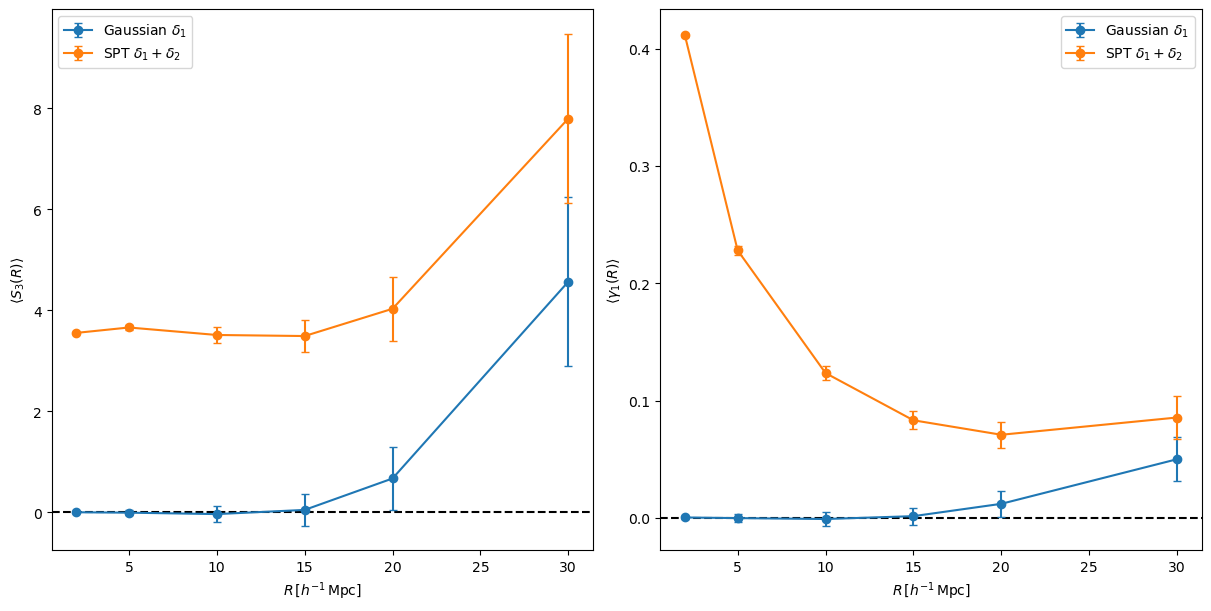

In [28]:
fig, ax = plt.subplots(ncols=2, figsize=(12, 6), layout="constrained")

# Reduced skewness
ax[0].axhline(0.0, color="k", ls="--")

ax[0].errorbar(R_values, S3g_mean,   yerr=S3g_sem,   marker="o", capsize=3, label=r"Gaussian $\delta_1$")
ax[0].errorbar(R_values, S3spt_mean, yerr=S3spt_sem, marker="o", capsize=3, label=r"SPT $\delta_1+\delta_2$")

ax[0].set_xlabel(r"$R\,[h^{-1}\,\mathrm{Mpc}]$")
ax[0].set_ylabel(r"$\langle S_3(R)\rangle$")
ax[0].legend()

# Standardized skewness
ax[1].axhline(0.0, color="k", ls="--")

ax[1].errorbar(R_values, gammag_mean,   yerr=gammag_sem,   marker="o", capsize=3, label=r"Gaussian $\delta_1$")
ax[1].errorbar(R_values, gammaspt_mean, yerr=gammaspt_sem, marker="o", capsize=3, label=r"SPT $\delta_1+\delta_2$")

ax[1].set_xlabel(r"$R\,[h^{-1}\,\mathrm{Mpc}]$")
ax[1].set_ylabel(r"$\langle\gamma_1(R)\rangle$")
ax[1].legend()

plt.savefig("../outputs/figures/02_s3_ensamble.png", dpi=200)
plt.show()

From this analysis, we check that at scales $R\lesssim15h^{-1}\mathrm{ Mpc}$ the gaussian ensamble is compatible with $\langle S_\mathrm{3,G}\rangle=0$, and its values are in agreement with zero within the ensamble scatter.

Compared to the gaussian density, however, the SPT contribution shows a systematic and non-negligible contribution on $S_3$. The higher value of $\gamma_1$ at small radii shows that there is a significant non-gaussianity of the field specially at those scales. However, at all ranges $2h^{-1}\mathrm{ Mpc}\lesssim R\lesssim15h^{-1}\mathrm{ Mpc}$ the $S_3$ and $\gamma_1$ values are increased from the gaussian model to the SPT density, as also shown by $\Delta\langle S_\mathrm{3}\rangle$ in the following table.

| $R\space[h^{-1}\mathrm{ Mpc}]$ |    $\langle S_\mathrm{3,G}\rangle$   |    $\langle S_\mathrm{3,SPT}\rangle$   |   $\Delta\langle S_\mathrm{3}\rangle$
|---|---:|---:|---|
   2  |   +0.002 $\pm$  0.011  |   +3.554 $\pm$  0.011   |  +3.552 $\pm$  0.005
   5  |   -0.006 $\pm$  0.054  |   +3.661 $\pm$  0.056  |   +3.667 $\pm$  0.007
  10  |   -0.034 $\pm$  0.159  |   +3.513 $\pm$  0.164  |   +3.547 $\pm$  0.018
  15  |   +0.048 $\pm$  0.309  |   +3.492 $\pm$  0.316  |   +3.443 $\pm$  0.026
  20  |   +0.671 $\pm$  0.627  |   +4.032 $\pm$  0.633  |   +3.361 $\pm$  0.035
  30  |   +4.569 $\pm$  1.671  |   +7.799 $\pm$  1.676  |   +3.230 $\pm$  0.046

In [29]:
print(" R      10⁶<m3_G> +/- SEM      |Z|")
print("-" * 36)
m3g_mean, m3g_sem = meanSem(higher_ensemble["m3_g"])

Z = np.abs(m3g_mean/m3g_sem)

for i, R in enumerate(R_values):
    print(
        f"{R:4.0f}   "
        f"{1e+6*m3g_mean[i]:+.5f} +/- {1e+6*m3g_sem[i]:+.5f}   "
        f"{Z[i]:.2f}"
    )

 R      10⁶<m3_G> +/- SEM      |Z|
------------------------------------
   2   +0.30100 +/- +1.74282   0.17
   5   -0.06254 +/- +0.80648   0.08
  10   -0.03519 +/- +0.24115   0.15
  15   +0.02422 +/- +0.09884   0.25
  20   +0.06544 +/- +0.06127   1.07
  30   +0.06583 +/- +0.02671   2.46


Looking only to the gaussian $\langle\sigma_1^3\rangle$ we can see that even its value at $30h^{-1}\mathrm{Mpc}$ is within 2.46$\sigma$ of zero within the scatter between the realizations.

# Realization testing (2d)

The following tests are as follows:
| test | $L$ | $N$ | objective |
|---|---:|---:|---|
| low-res | 500 | 128 | convergence |
| med-res | 500 | 192 | convergence |
| fiducial | 500 | 256 | comparision / already calculated |
| small-box | 250 | 128 | volume, same $\Delta x$ |
| med-box | 375 | 192 | volume, same $\Delta x$ |

In [9]:
configs = {
    "low-res":   {"L": 500.0, "N": 128},
    "med-res":   {"L": 500.0, "N": 192},
    "fiducial":  {"L": 500.0, "N": 256},
    "small-box": {"L": 250.0, "N": 128},
    "med-box":   {"L": 375.0, "N": 192},
}

D_test = D_spt
dealiasing_frac = 2.0 / 3.0
R_values_2d = np.array([5.0, 10.0, 15.0, 20.0])

seeds_2d = np.arange(10)
resolution_names = ["low-res", "med-res", "fiducial"]
box_names = ["small-box", "med-box", "fiducial"]

## Resolution

In [8]:
resolution_runs = {}

for name in resolution_names:
    resolution_runs[name] = spt.runSptDiagnosticEnsemble(configs[name], seeds_2d, D_test, 
                                                         classPower, R_values_2d, dealiasing_frac)

N=128, L=  500: 1/10
N=128, L=  500: 2/10
N=128, L=  500: 3/10
N=128, L=  500: 4/10
N=128, L=  500: 5/10
N=128, L=  500: 6/10
N=128, L=  500: 7/10
N=128, L=  500: 8/10
N=128, L=  500: 9/10
N=128, L=  500: 10/10
N=192, L=  500: 1/10
N=192, L=  500: 2/10
N=192, L=  500: 3/10
N=192, L=  500: 4/10
N=192, L=  500: 5/10
N=192, L=  500: 6/10
N=192, L=  500: 7/10
N=192, L=  500: 8/10
N=192, L=  500: 9/10
N=192, L=  500: 10/10
N=256, L=  500: 1/10
N=256, L=  500: 2/10
N=256, L=  500: 3/10
N=256, L=  500: 4/10
N=256, L=  500: 5/10
N=256, L=  500: 6/10
N=256, L=  500: 7/10
N=256, L=  500: 8/10
N=256, L=  500: 9/10
N=256, L=  500: 10/10


In [10]:
def ensemblePowerMean(runs, key):
    values = np.asarray([run[key] for run in runs])
    return values.mean(axis=0), values.std(axis=0, ddof=1) / np.sqrt(values.shape[0])

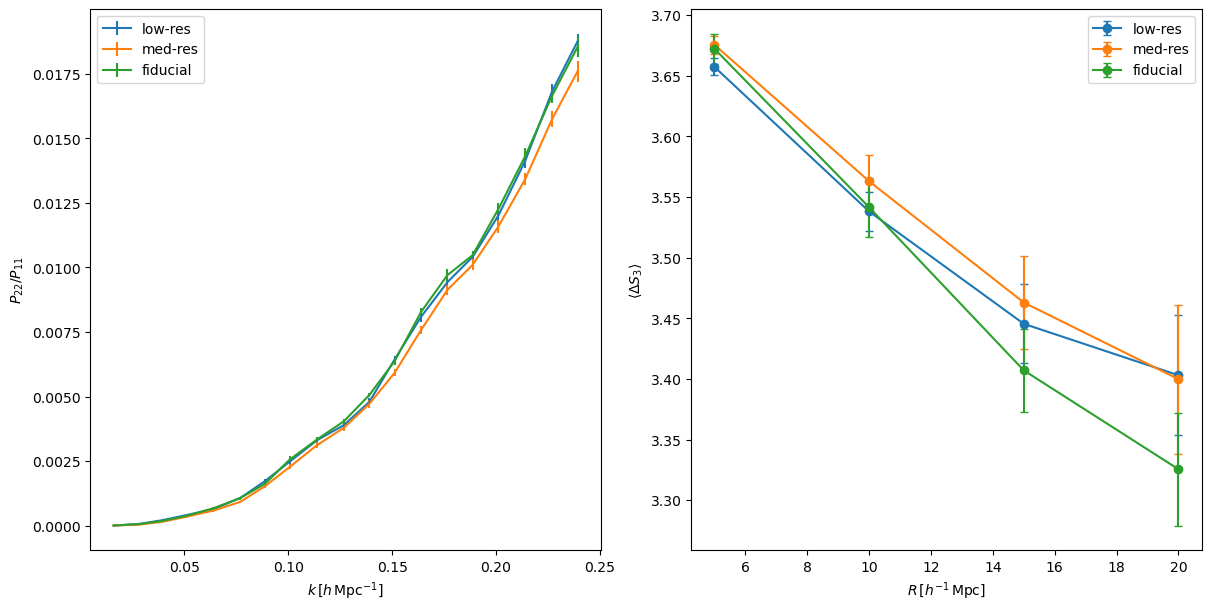

In [12]:
fig, ax = plt.subplots(ncols=2, figsize=(12, 6), layout="constrained")

for name in resolution_names:
    runs = resolution_runs[name]

    ratios = np.asarray([run["P22"] / run["P11"] for run in runs])

    ratio_mean = ratios.mean(axis=0)
    ratio_sem = ratios.std(axis=0, ddof=1) / np.sqrt(len(runs))

    k = runs[0]["kbin"]
    kcommon = 0.3 * np.pi * configs["low-res"]["N"] / configs["low-res"]["L"]
    mask = k <= kcommon

    ax[0].errorbar(k[mask], ratio_mean[mask], yerr=ratio_sem[mask], label=name)

    deltaS3 = np.asarray([run["S3_spt"] - run["S3_g"] for run in resolution_runs[name]])

    mean = deltaS3.mean(axis=0)
    sem = deltaS3.std(axis=0, ddof=1) / np.sqrt(deltaS3.shape[0])

    ax[1].errorbar(R_values_2d, mean, yerr=sem, marker="o", capsize=3, label=name)

ax[0].set_xlabel(r"$k\,[h\,\mathrm{Mpc}^{-1}]$")
ax[0].set_ylabel(r"$P_{22}/P_{11}$")
ax[0].legend()

ax[1].set_xlabel(r"$R\,[h^{-1}\,\mathrm{Mpc}]$")
ax[1].set_ylabel(r"$\langle\Delta S_3\rangle$")
ax[1].legend()

plt.savefig("../outputs/figures/02_resolution.png", dpi=200)
plt.show()

At the common frequencies of $k\lesssim k_\mathrm{Ny}(N=128)\simeq0.24 h\mathrm{Mpc}^{-1}$ chosen, both the $P_{22}/P_{11}$ and the $\langle\Delta S_3\rangle$ show good agreement between eachother within the scatter. Therefore, this resolution range is already reasonably converged for this quantity at such confidence frequencies. 

## Box size

In [14]:
box_runs = {}

for name in box_names:
    box_runs[name] = spt.runSptDiagnosticEnsemble(configs[name], seeds_2d, D_test,
                                              classPower, R_values_2d, dealiasing_frac)

N=128, L=  250: 1/10
N=128, L=  250: 2/10
N=128, L=  250: 3/10
N=128, L=  250: 4/10
N=128, L=  250: 5/10
N=128, L=  250: 6/10
N=128, L=  250: 7/10
N=128, L=  250: 8/10
N=128, L=  250: 9/10
N=128, L=  250: 10/10
N=192, L=  375: 1/10
N=192, L=  375: 2/10
N=192, L=  375: 3/10
N=192, L=  375: 4/10
N=192, L=  375: 5/10
N=192, L=  375: 6/10
N=192, L=  375: 7/10
N=192, L=  375: 8/10
N=192, L=  375: 9/10
N=192, L=  375: 10/10
N=256, L=  500: 1/10
N=256, L=  500: 2/10
N=256, L=  500: 3/10
N=256, L=  500: 4/10
N=256, L=  500: 5/10
N=256, L=  500: 6/10
N=256, L=  500: 7/10
N=256, L=  500: 8/10
N=256, L=  500: 9/10
N=256, L=  500: 10/10


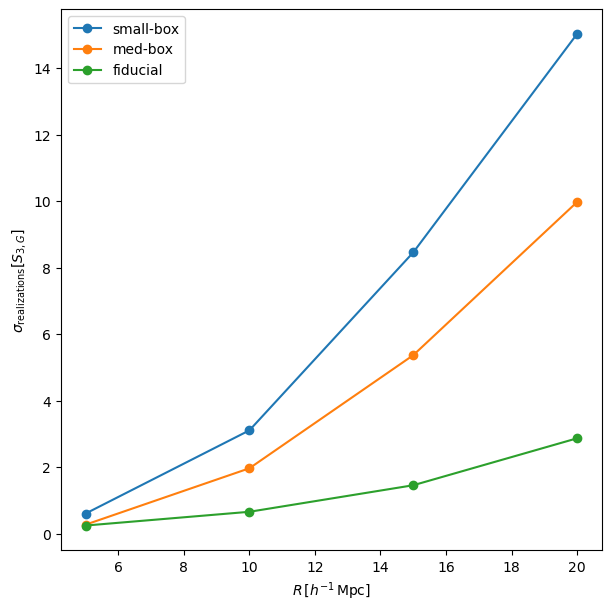

configuration     dx       volume
small-box       1.953      1.562e+07
med-box         1.953      5.273e+07
fiducial        1.953      1.250e+08


In [16]:
fig, ax = plt.subplots(figsize=(6, 6), layout="constrained")

for name in box_names:
    S3g = np.asarray([run["S3_g"] for run in box_runs[name]])
    scatter = S3g.std(axis=0, ddof=1)

    ax.plot(R_values_2d, scatter, marker="o", label=name)

ax.set_xlabel(r"$R\,[h^{-1}\,\mathrm{Mpc}]$")
ax.set_ylabel(r"$\sigma_{\rm realizations}[S_{3,G}]$")
ax.legend()

plt.savefig("../outputs/figures/02_boxsize.png", dpi=200)
plt.show()

print("configuration     dx       volume")
for name in box_names:
    Lc = configs[name]["L"]
    Nc = configs[name]["N"]
    print(f"{name:12s}   {Lc / Nc:6.3f}   {Lc**3:12.3e}")

In [17]:
iR = np.where(R_values_2d == 10.0)[0][0]

print("configuration    std(S3_G)    std(S3_SPT)    std(Delta S3)")
print("-" * 62)

for name in box_names:
    runs = box_runs[name]
    
    S3g = np.asarray([run["S3_g"][iR] for run in runs])
    S3spt = np.asarray([run["S3_spt"][iR] for run in runs])
    dS3 = S3spt - S3g

    print(f"{name:12s}   {S3g.std(ddof=1):9.4f}   {S3spt.std(ddof=1):11.4f}   {dS3.std(ddof=1):12.4f}")

configuration    std(S3_G)    std(S3_SPT)    std(Delta S3)
--------------------------------------------------------------
small-box         3.1082        2.9774         0.2053
med-box           1.9671        1.9340         0.1030
fiducial          0.6585        0.6732         0.0772


Mantaining the same fixed $\Delta x=L/N=1.953 h^{-1}\mathrm{Mpc}$ resolution across different $L$ box sizes, the scatter of $S_\mathrm{3,G}$ systematically decreases with higher box sizes, specially at large $R$ scales. Therefore we show that the measured skewness at large scales is particularly dependent on the box size sampled.

## Amplitude

In [19]:
D_factors = np.array([0.5, 1.0, 1.5])

amplitude_runs = {}

for factor in D_factors:
    amplitude_runs[factor] = spt.oneSptDiagnostic(256, 500.0, 1234, factor * D_spt, classPower, 
                                              R_values_2d, dealiasing_frac=dealiasing_frac)

In [23]:
k_target = 0.15

P11_at_k = []
P22_at_k = []

for factor in D_factors:
    run = amplitude_runs[factor]

    ik = np.argmin(np.abs(run["kbin"] - k_target))
    P11_at_k.append(run["P11"][ik])
    P22_at_k.append(run["P22"][ik])

P11_at_k = np.asarray(P11_at_k)
P22_at_k = np.asarray(P22_at_k)

print("D/Dfid    P11/P11fid    expected    P22/P22fid    expected")

for i, factor in enumerate(D_factors):
    print(
        f"{factor:5.2f}      "
        f"{P11_at_k[i] / P11_at_k[1]:10.5f}   "
        f"{factor**2:8.5f}      "
        f"{P22_at_k[i] / P22_at_k[1]:10.5f}   "
        f"{factor**4:8.5f}"
    )

print()
for factor in D_factors:
    run = amplitude_runs[factor]
    iR = np.where(R_values_2d == 10.0)[0][0]

    print(
        f"R = 10.0   "
        f"D/Dfid={factor:4.2f}   "
        f"S3={run['S3_spt'][iR]:+.4f}   "
        f"Delta S3={run['S3_spt'][iR]-run['S3_g'][iR]:+.4f}   "
        f"gamma1={run['gamma_spt'][iR]:+.4f}   "
        f"Delta gamma1={run['gamma_spt'][iR]-run['gamma_g'][iR]:+.4f}   "
    )

D/Dfid    P11/P11fid    expected    P22/P22fid    expected
 0.50         0.25000    0.25000         0.06250    0.06250
 1.00         1.00000    1.00000         1.00000    1.00000
 1.50         2.25000    2.25000         5.06250    5.06250

R = 10.0   D/Dfid=0.50   S3=+1.8692   Delta S3=+3.5562   gamma1=+0.0329   Delta gamma1=+0.0627   
R = 10.0   D/Dfid=1.00   S3=+2.7033   Delta S3=+3.5468   gamma1=+0.0953   Delta gamma1=+0.1251   
R = 10.0   D/Dfid=1.50   S3=+2.9680   Delta S3=+3.5303   gamma1=+0.1572   Delta gamma1=+0.1869   


The amplitude test verifies that $P_{11}\propto D^2$, $P_{22}\propto D^4$ as expected with a precise agreement.

At first, it may seem that $S_\mathrm{3,SPT}$ is dependent on amplitude $D$. We expect that, by scale a field by $\alpha$, then $m_3\propto\alpha^3$ and $\sigma^4\propto\alpha^4$, such that $S_{3,G}(\alpha D)= \alpha^{-1}S_{3,G}(D)$. Since we are using the same seed, however, there is a common fluctuation between the same realization scaled by $\alpha=(0.5, 1.0, 1.5)$. We can show that the $\Delta S_3$ is consistent within the scaling, and therefore independent of $D$.